In [49]:
!pip -q install ucimlrepo

In [50]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

student_data = fetch_ucirepo(id=320)

table = pd.concat(
    [student_data.data.features, student_data.data.targets],
    axis=1
)

print("Dataset size:", table.shape)
display(table.head())

Dataset size: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


In [51]:
print("Dataset size:", table.shape)
print("Missing values:", table.isna().sum().sum())
print("Duplicate rows", table.duplicated().sum())

display(table[["studytime", "absences", "G1", "G2", "G3"]].head())

Dataset size: (649, 33)
Missing values: 0
Duplicate rows 0


,studytime,absences,G1,G2,G3
0,2,4,0,11,11
1,2,2,9,11,11
2,2,6,12,13,12
3,3,0,14,14,14
4,2,0,11,13,13


In [52]:
table[["studytime", "absences", "G1", "G2", "G3"]].describe()

,studytime,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000
mean,1.930663,3.659476,11.399076,11.570108,11.906009
std,0.829510,4.640759,2.745265,2.913639,3.230656
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,10.000000,10.000000,10.000000
50%,2.000000,2.000000,11.000000,11.000000,12.000000
75%,2.000000,6.000000,13.000000,13.000000,14.000000
max,4.000000,32.000000,19.000000,19.000000,19.000000


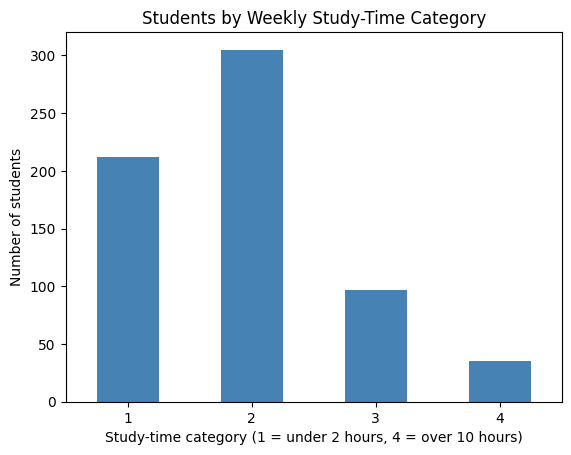

In [53]:
import matplotlib.pyplot as plt

study_counts = table["studytime"].value_counts().sort_index()

study_counts.plot(kind="bar", color="steelblue")
plt.title("Students by Weekly Study-Time Category")
plt.xlabel("Study-time category (1 = under 2 hours, 4 = over 10 hours)")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.show()

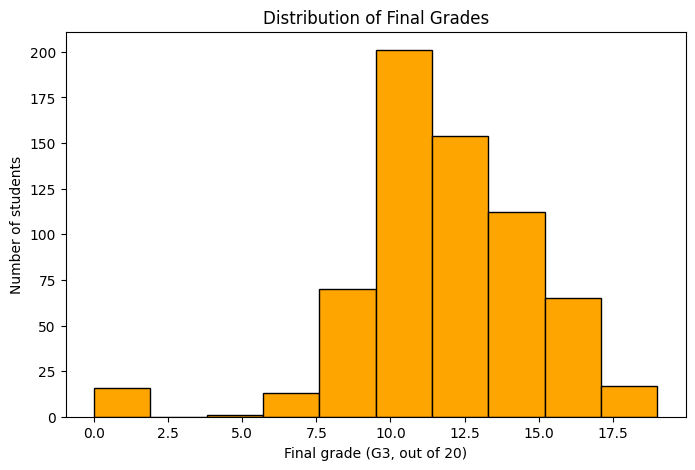

In [54]:
plt.figure(figsize=(8, 5))
plt.hist(table["G3"], bins=10, edgecolor="black", color="orange")
plt.title("Distribution of Final Grades")
plt.xlabel("Final grade (G3, out of 20)")
plt.ylabel("Number of students")
plt.show()

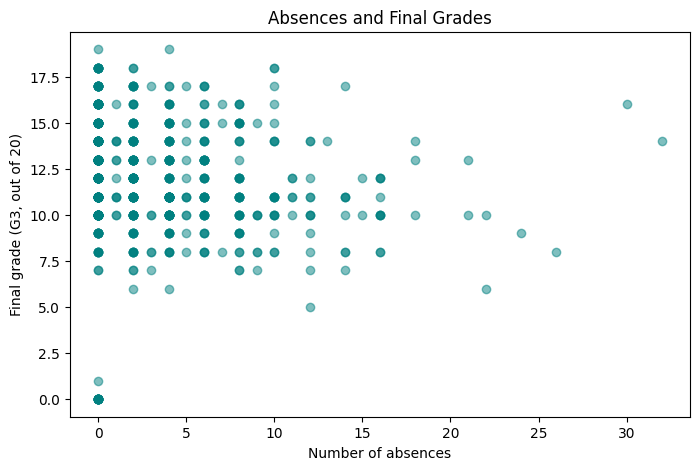

In [55]:
plt.figure(figsize=(8, 5))
plt.scatter(table["absences"], table["G3"], alpha=0.5, color="teal")
plt.title("Absences and Final Grades")
plt.xlabel("Number of absences")
plt.ylabel("Final grade (G3, out of 20)")
plt.show()

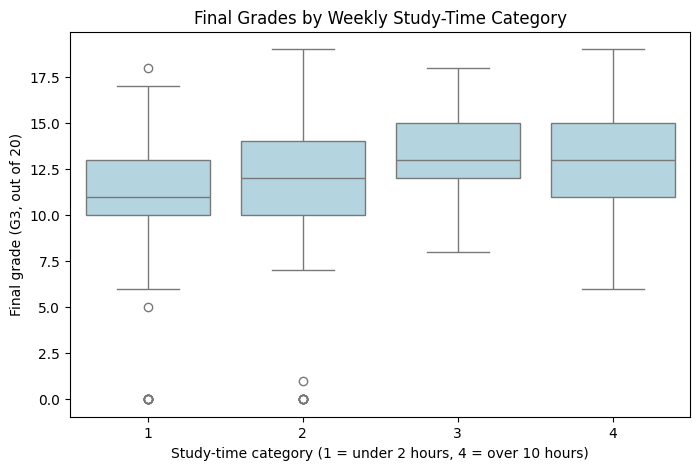

In [56]:
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(data=table, x="studytime", y="G3", color="lightblue")
plt.title("Final Grades by Weekly Study-Time Category")
plt.xlabel("Study-time category (1 = under 2 hours, 4 = over 10 hours)")
plt.ylabel("Final grade (G3, out of 20)")
plt.show()

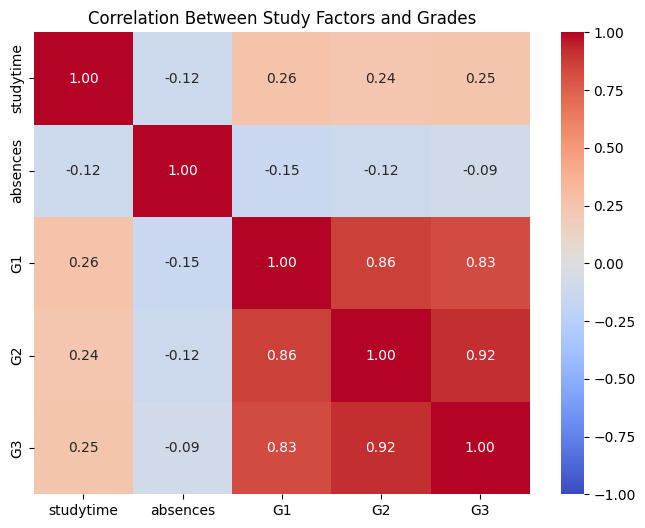

In [57]:
columns_to_check = ["studytime", "absences", "G1", "G2", "G3"]
correlations = table[columns_to_check].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Between Study Factors and Grades")
plt.show()

In [58]:
from sklearn.model_selection import train_test_split

features = table[["studytime", "absences", "G1", "G2"]]
target = table["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Input columns:", list(features.columns))

Training records: 519
Testing records: 130
Input columns: ['studytime', 'absences', 'G1', 'G2']


In [59]:
from sklearn.linear_model import LinearRegression
import pandas as pd

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

results = pd.DataFrame({
    "Actual grade": y_test.values[:10],
    "Predicted grade": predictions[:10].round(1)
})

display(results)

,Actual grade,Predicted grade
0,19,18.6
1,12,11.3
2,18,18.7
3,11,11.2
4,11,11.7
5,17,16.9
6,18,17.7
7,8,9.6
8,10,10.4
9,11,10.5


In [60]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.2f} marks")
print(f"RMSE: {rmse:.2f} marks")
print(f"R²:   {r2:.2f}")

MAE:  0.75 marks
RMSE: 1.17 marks
R²:   0.86


In [61]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    LinearRegression(),
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("R² for the five folds:", cv_scores.round(2))
print(f"Average cross-validation R²: {cv_scores.mean():.2f}")

R² for the five folds: [0.88 0.75 0.86 0.88 0.87]
Average cross-validation R²: 0.85


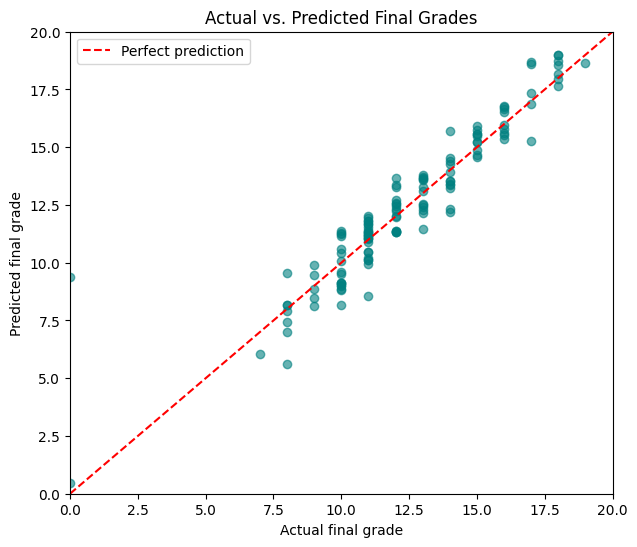

In [62]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions, alpha=0.6, color="teal")
plt.plot([0, 20], [0, 20], "r--", label="Perfect prediction")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.title("Actual vs. Predicted Final Grades")
plt.xlabel("Actual final grade")
plt.ylabel("Predicted final grade")
plt.legend()
plt.show()

In [63]:
new_student = pd.DataFrame(
    [[2, 3, 12, 13]],
    columns=["studytime", "absences", "G1", "G2"]
)

predicted_grade = model.predict(new_student)[0]

print(f"Predicted final grade: {predicted_grade:.1f} / 20")

Predicted final grade: 13.3 / 20


In [64]:
coefficients = pd.DataFrame({
    "Input feature": features.columns,
    "Model coefficient": model.coef_.round(3)
})

display(coefficients)

,Input feature,Model coefficient
0,studytime,0.119
1,absences,0.024
2,G1,0.188
3,G2,0.879


In [65]:
import numpy as np

review_threshold = 10

test_results = pd.DataFrame({
    "Actual grade": y_test.values,
    "Predicted grade": predictions.round(1)
})

test_results["Review flag"] = np.where(
    test_results["Predicted grade"] < review_threshold,
    "Review suggested",
    "No flag"
)

print("Project review threshold:", review_threshold, "out of 20")
print("Records flagged for review:", (test_results["Review flag"] == "Review suggested").sum())
display(test_results.head())

Project review threshold: 10 out of 20
Records flagged for review: 27


,Actual grade,Predicted grade,Review flag
0,19,18.6,No flag
1,12,11.3,No flag
2,18,18.7,No flag
3,11,11.2,No flag
4,11,11.7,No flag


## Results and Interpretation

The dataset has 649 student records and 33 columns. The checks found 0 missing values and 0 duplicate rows. The project used study-time category, absences and first- and second-period grades (G1 and G2) to predict grade (G3).

The final-grade histogram shows that many grades fall in the middle of the 0–20 scale. In the scatter plot grades vary across absence counts. There are fewer students with many absences. The box plot shows higher median grades in the higher study-time categories although the grade ranges overlap.

The correlation heatmap shows positive relationships between earlier grades and final grade: G1–G3 is 0.83 and G2–G3 is 0.92. Study-time category has a positive relationship with G3 (0.25) while absences has a very weak negative relationship with G3 (-0.09). These relationships do not prove that one factor causes another.

A Linear Regression model was trained using study-time category, absences, G1 and G2. It was evaluated on 130 held-out test records. The MAE was 0.75 marks the RMSE was 1.17 marks and R² was 0.86. Five- cross-validation produced an average R² of 0.85 with fold scores ranging from 0.75 to 0.88.

For a review feature the project flagged test predictions below a chosen threshold of 10 out of 20. This flagged 27 records. The threshold is a project design choice for demonstration; a flag is not a diagnosis or a decision about a student.

## Limitations

The dataset describes students from two schools in Portugal so the results may not generalize to schools or countries. Study time is recorded in four categories than exact hours and absences are recorded instead of attendance percentage. G1 and G2 are strongly related to G3 so the model’s good performance partly reflects having earlier grades available. The model can still make errors. The review threshold should not be treated as an official school policy.

## Conclusion

This project used student information to explore grade patterns and predict final grades with Linear Regression. On the held-out test records predictions were generally close, to grades and cross-validation showed a similar average result. The charts and model can help explore patterns in this dataset. Predictions should be treated as estimates and checked by a person.

# Minor Project: Student Performance Analysis and Prediction System

**Student:** Aditya Rathore  **Program:** AIML with Python Training Program, September 2026 Batch

## Introduction and Problem Statement

Academic performance can be linked to factors such as study time, absences and earlier grades. This project looks at those patterns in a student dataset. Uses Linear Regression to estimate student final grades.

## Objectives

- Inspect and clean a student performance dataset.

- Explore study time, absences and grade patterns using statistics and charts.

- Train a Linear Regression model to predict student grades.

- Evaluate predictions on held‑out records.

- Present the results and limitations clearly.

## Dataset Description and Source

The project uses the UCI Student Performance dataset, fetched from the UCI Machine Learning Repository (dataset 320). The loaded data contains 649 records and 33 columns. The selected fields are `studytime` `absences` `G1` `G2` and `G3`. In this dataset study time is recorded in four weekly‑hour categories absences are a count and grades use a 0–20 scale.

**Source:** Cortez, P. (2008). *Student Performance*. UCI Machine Learning Repository. Https://doi.org/10.24432/C5TG7T

## Data Preparation and Method

The data was checked for missing values and duplicate rows; both counts were zero. The model used `studytime` `absences` `G1` and `G2` as input features and `G3` as the prediction target. The records were split into 519 training records and 130 test records. Linear Regression was trained on the training records. Evaluated on the held‑out test records. Five‑fold cross‑validation was also applied to the training data.

## Results

On the held‑out test records the model achieved an MAE of 0.75 marks, an RMSE of 1.17 marks and an R² score of 0.86. The five‑fold cross‑validation R² scores were 0.88, 0.75 0.86 0.88 and 0.87 with an average of 0.85.

A project‑defined review threshold of 10 out of 20 flagged 27 test predictions for human review. This is a demonstration feature, not a school rule or a decision about any student.

## Future Improvements

Future work could use a dataset with attendance percentages and exact study hours validate the model on data from other schools and compare additional regression models. Any review threshold should be selected with input, from the school.

## References

Cortez, P. (2008). *Student Performance*. UCI Machine Learning Repository. Https://doi.org/10.24432/C5TG7T

# Student Performance Analysis and Prediction System

## Project Overview

This project looks at student study-time groups, absences and past grades then uses Linear Regression to guess grades. It also has a check flag for predictions that're below a project chosen limit.

## Dataset

The project uses the UCI Student Performance dataset, dataset number 320. The data has 649 entries and 33 columns. The model uses studytime, absences, G1 and G2 to predict G3.

Source: Cortez, P. (2008). UCI Machine Learning Repository. Https://doi.org/10.24432/C5TG7T

## Technologies

- Python

- Pandas and NumPy

- Matplotlib and Seaborn

- Scikit-learn

- Google Colab

## How to Run

1. Open student_performance_analysis.ipynb in Google Colab.

2. Run the notebook cells from top to bottom.

3. The first setup cell installs ucimlrepo; the notebook then gets the dataset from UCI.

4. Look at the charts, model predictions and results in the notebook.

## Model and Results

The project uses Linear Regression with study-time groups, absences and first and second period grades as inputs. On the test set MAE was 0.75 RMSE was 1.17 and R² was 0.86. The average five-fold cross-validation R² was 0.85.

## Limitations

The data comes from students at two schools in Portugal. Study time is split into groups and absences are used of attendance percentage. The model uses grades, which are very connected to the final grade. Predictions are guesses and need a person to check them. The check limit of 10 out of 20 is a choice, for the project, not a school rule.

## Project Files

- student_performance_analysis.ipynb. Code, charts, model and findings

- student_performance_dataset.csv. Dataset used in the project

- Project_Report.pdf. Project report

- README.md. Project overview and run instructions

- screenshots/. Proof of charts and results

In [66]:
table.to_csv("student_performance_dataset.csv", index=False)
print("Saved student_performance_dataset.csv")

Saved student_performance_dataset.csv
